In [6]:

import numpy as np
import pandas as pd

from pathlib import Path

DATA_PATH = Path("../data/processed")
OUTPUT_PATH = Path("../data/processed")

train_df = pd.read_csv(
    DATA_PATH / "train_FD001_with_RUL.csv"
)

print("Dataset loaded successfully!")
print("Shape:", train_df.shape)

display(train_df.head())


Dataset loaded successfully!
Shape: (20631, 28)


,unit_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,max_cycle,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,192,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,192,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,192,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,192,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,192,187


In [7]:

sensor_cols = [
    col for col in train_df.columns
    if col.startswith("sensor_")
]

print("Number of sensors:", len(sensor_cols))
print("Sensor columns:", sensor_cols)


Number of sensors: 21
Sensor columns: ['sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']


In [8]:

def create_features(data, window=5):

    # Work on a copy to preserve the original data
    df = data.copy()

    # Sort observations chronologically for every engine
    df = df.sort_values(
        ["unit_id", "cycle"]
    ).reset_index(drop=True)

    sensor_cols = [
        col for col in df.columns
        if col.startswith("sensor_")
    ]

    # Generate features separately for each engine
    for sensor in sensor_cols:

        # 1. Rolling mean over recent cycles
        df[f"{sensor}_rolling_mean"] = (
            df.groupby("unit_id")[sensor]
            .transform(
                lambda s: s.rolling(
                    window=window,
                    min_periods=1
                ).mean()
            )
        )

        # 2. Rolling standard deviation
        df[f"{sensor}_rolling_std"] = (
            df.groupby("unit_id")[sensor]
            .transform(
                lambda s: s.rolling(
                    window=window,
                    min_periods=2
                ).std()
            )
            .fillna(0)
        )

        # 3. Change from previous operational cycle
        df[f"{sensor}_change"] = (
            df.groupby("unit_id")[sensor]
            .diff()
            .fillna(0)
        )

    return df


# Apply feature engineering
train_features = create_features(
    train_df,
    window=5
)

print("Feature engineering completed!")
print("Original shape:", train_df.shape)
print("New shape:", train_features.shape)

display(train_features.head())


Feature engineering completed!
Original shape: (20631, 28)
New shape: (20631, 91)


,unit_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_18_change,sensor_19_rolling_mean,sensor_19_rolling_std,sensor_19_change,sensor_20_rolling_mean,sensor_20_rolling_std,sensor_20_change,sensor_21_rolling_mean,sensor_21_rolling_std,sensor_21_change
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,0.0,100.0,0.0,0.0,39.060000,0.000000,0.00,23.419000,0.000000,0.0000
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,0.0,100.0,0.0,0.0,39.030000,0.042426,-0.06,23.421300,0.003253,0.0046
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,0.0,100.0,0.0,0.0,39.003333,0.055076,-0.05,23.395600,0.044573,-0.0794
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,0.0,100.0,0.0,0.0,38.972500,0.076322,-0.07,23.390175,0.037977,0.0297
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,0.0,100.0,0.0,0.0,38.958000,0.073621,0.02,23.393020,0.033498,0.0305


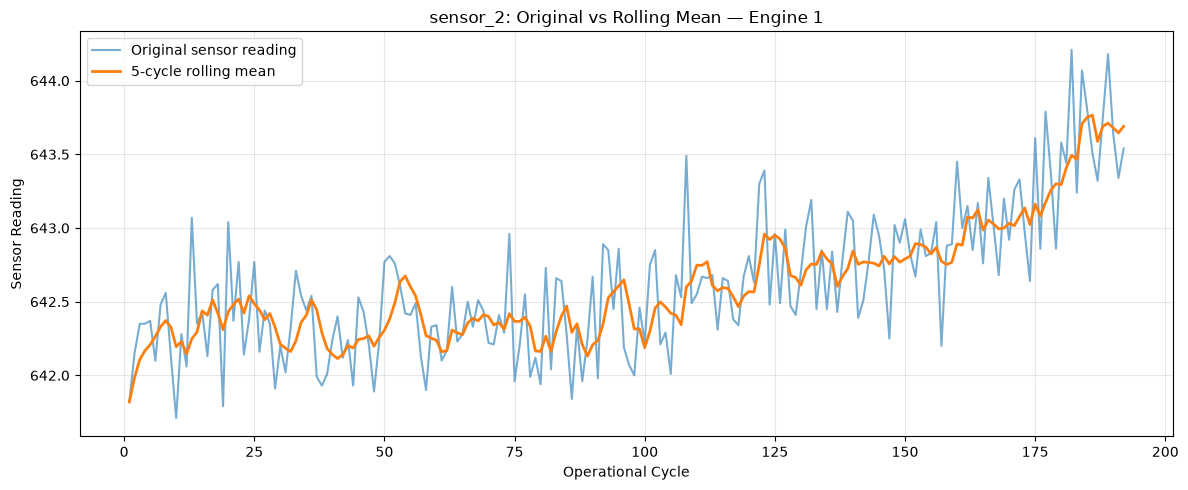

In [9]:

import matplotlib.pyplot as plt

# Select one engine for visualisation
engine_id = 1

engine_data = (
    train_features[
        train_features["unit_id"] == engine_id
    ]
    .sort_values("cycle")
)

sensor = "sensor_2"

plt.figure(figsize=(12, 5))

plt.plot(
    engine_data["cycle"],
    engine_data[sensor],
    label="Original sensor reading",
    alpha=0.6
)

plt.plot(
    engine_data["cycle"],
    engine_data[f"{sensor}_rolling_mean"],
    label="5-cycle rolling mean",
    linewidth=2
)

plt.title(
    f"{sensor}: Original vs Rolling Mean — Engine {engine_id}"
)

plt.xlabel("Operational Cycle")
plt.ylabel("Sensor Reading")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [10]:

output_file = (
    OUTPUT_PATH / "train_FD001_engineered.csv"
)

train_features.to_csv(
    output_file,
    index=False
)

print("Engineered dataset saved!")
print("File:", output_file)
print("Final shape:", train_features.shape)


Engineered dataset saved!
File: ..\data\processed\train_FD001_engineered.csv
Final shape: (20631, 91)
